In [ ]:
from notebook_setup import add_project_path_to_notebook

add_project_path_to_notebook()

from edmri.paths import CONFIG_PATH, PROJECT_ROOT, RESULTS_PATH, EXAMPLE_DATA_PATH, CONFIG_PATH

print("Found project root and path to simulated data at the following locations")
print(f"Project root: {PROJECT_ROOT}")
print(f"Results path: {RESULTS_PATH}")
print(f"Example data path: {EXAMPLE_DATA_PATH}")
print(f"Configuration files path: {CONFIG_PATH}")

KeyboardInterrupt: 

In [ ]:
MODEL = "SANDI"

In [ ]:
import sys
import numpy as np

RUN_SIMULATION = True

if RUN_SIMULATION:
    !{sys.executable} "{PROJECT_ROOT}/examples/generate_simulation_data.py" "--model" {MODEL}
    #!{sys.executable} "{PROJECT_ROOT}/examples/generate_simulation_data.py"


#
super_protocol_path = EXAMPLE_DATA_PATH / MODEL / "superdesign_protocol.txt"
super_signals_path = EXAMPLE_DATA_PATH / MODEL / "superdesign_signals.npy"
super_targets_path = EXAMPLE_DATA_PATH / MODEL / "superdesign_targets.npy"

super_protocol = np.atleast_2d(np.loadtxt(super_protocol_path))
super_signals = np.load(super_signals_path)
super_targets = np.load(super_targets_path)



Simulated MRI data generation complete.
Model:       SANDI
Signals dim:     (1000, 96)
Targets dim:     (1000, 5)
Protocol dim: (96, 3)
Saved to:    examples/data/SANDI
Protocol: Default superdesign for SANDI model.


In [ ]:
print(super_protocol.shape)
print(super_protocol.dtype)

(96, 3)
float64


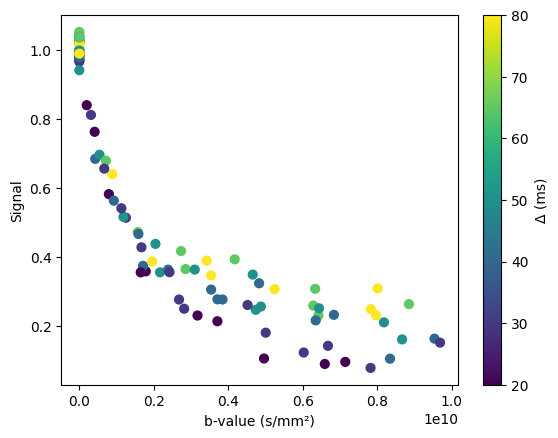

In [ ]:
import matplotlib.pyplot as plt

from edmri.models.sandi import _calculate_b

b = _calculate_b(super_protocol[:, 0] * 1e-3, super_protocol[:, 1] * 1e-3, super_protocol[:, 2] * 1e-3)

Delta = super_protocol[:, 1] 

plt.scatter(
        b,
        super_signals[20, :],
        c=Delta,
        cmap="viridis",
        s=40,
    )
    
plt.ylabel("Signal")
plt.xlabel("b-value (s/mm²)")
plt.colorbar(label="Δ (ms)")

In [ ]:
#run tadred
RUN_OPTIMISE = True

if RUN_OPTIMISE:
    !edmri-optimise \
        --example {MODEL} \
        --config "{CONFIG_PATH}/optimise_default.yaml" \
        "data.input={super_signals_path}" \
        "data.target={super_targets_path}" \
        "data.superdesign={super_protocol_path}" 

    
    
    

INFO:tadred.data_processing:concatenated ['train'] on voxel dim
INFO:tadred.data_processing:Target data found
INFO:tadred.data_processing:concatenated ['val'] on voxel dim
INFO:tadred.data_processing:Target data found
INFO:tadred.data_processing:concatenated ['test'] on voxel dim
INFO:tadred.data_processing:Target data found
INFO:tadred.tadred_main:data_norm:
  data_fil: null
  data_train_subjs:
  - train
  data_val_subjs:
  - val
  data_test_subjs:
  - test
  data_normalization: original-measurement
output:
  out_base: results/optimisation/examples
  proj_name: tadred_results
  run_name: tadred_output_
network:
  num_units_score:
  - 1000
  - 1000
  num_units_task:
  - 1000
  - 1000
  score_activation: doublesigmoid
tadred_train_eval:
  feature_set_sizes_Ci:
  - 96
  - 78
  - 60
  - 42
  - 24
  feature_set_sizes_evaluated:
  - 96
  - 78
  - 60
  - 42
  - 24
  epochs: 1000
  epochs_fix_sigma: 25
  epochs_decay_sigma: 10
  epochs_decay: 10
train_pytorch:
  dataloader_params:
    batch_s

In [ ]:
!ls results/optimisation/examples/tadred_results

full_results            optimised_protocol.txt
optimised_indices.txt   trained_task_network.pt


In [ ]:
#load the output

"results/optimisation

Text(0.5, 0, 'b-value (s/mm²)')

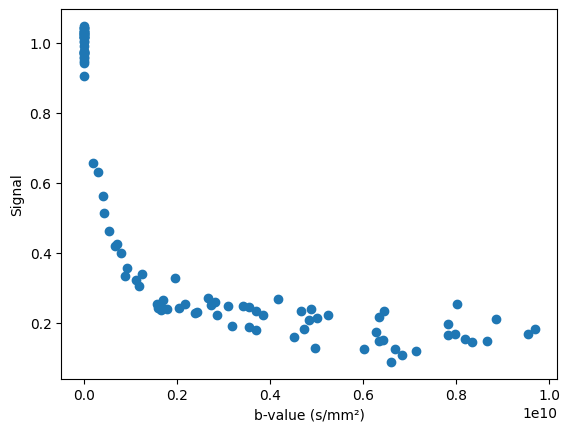

In [ ]:
#plot the optimised protocol and compare to the superdesign

import matplotlib.pyplot as plt

from edmri.models.sandi import _calculate_b

b = _calculate_b(super_protocol[:, 0] * 1e-3, super_protocol[:, 1] * 1e-3, super_protocol[:, 2] * 1e-3)

plt.plot(b, super_signals[0,:], 'o')

Delta = super_protocol[:, 1] 

    
plt.ylabel("Signal")
plt.xlabel("b-value (s/mm²)")


In [ ]:
#simulate new data using the optimised protocol

Using configuration file: /Users/paddyslator/python/ED_MRI_CLEAN/ED_MRI/edmri/conf/optimise_default.yaml
